# Subscription CFO lab: channel experiments, scaling, and the CTV halo

This synthetic subscription scenario begins with paid search and affiliate acquisition, then tests three unproven channels:

- **Podcast** performs materially better than its underwriting curve and can be scaled.
- **Display** retains poorly and destroys value, so it is stopped.
- **CTV** looks unattractive under direct attribution, but coincides with better retention and monetization across existing cohorts—a portfolio halo that direct ROAS misses.

The CFO uses Theseus to reconcile observations with the prior forecast, re-underwrite every cohort, optimize a fixed future acquisition budget, and compare direct-attribution and incrementality-aware cash plans.

### Start here and related reading

- [Theseus API introduction and walkthrough](../../Theseus_Walkthrough.ipynb)
- [Building a marketing P&L using LTV and ROAS](https://mobiledevmemo.com/ltv-roas-marketing-p-and-l/)
- [Optimization models in digital advertising](https://mobiledevmemo.com/optimization-models-in-digital-advertising/)
- [How to manage marketing spend during a recession](https://mobiledevmemo.com/how-to-manage-marketing-spend-during-a-recession/)
- [The power of cohort compounding](https://mobiledevmemo.com/podcast-the-power-of-cohort-compounding-with-nilay-patel/)

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.figure import Figure
from scipy.optimize import linprog

import theseus_growth as tg

%matplotlib inline
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists())
DATA = ROOT / "examples" / "data" / "subscription"

cohorts = pd.read_csv(DATA / "cohorts.csv")
curves = pd.read_csv(DATA / "curves.csv")
observations = pd.read_csv(DATA / "observations.csv")
acquisition_spend = pd.read_csv(DATA / "acquisition_spend.csv")
curve_assumptions = pd.read_csv(DATA / "curve_assumptions.csv")
channel_assumptions = pd.read_csv(DATA / "channel_assumptions.csv").set_index("channel")
scenario_assumptions = pd.read_csv(DATA / "scenario_assumptions.csv").set_index("assumption")["value"]

AS_OF = int(scenario_assumptions["as_of"])
FORECAST_END = int(scenario_assumptions["forecast_end"])
CTV_LAUNCH_DAY = int(scenario_assumptions["ctv_launch_day"])
STARTING_CASH = float(scenario_assumptions["starting_cash"])
DAILY_OPERATING_CASH_FLOW = float(scenario_assumptions["daily_non_marketing_cash_flow"])
FUTURE_BUDGET = float(scenario_assumptions["future_new_channel_budget"])
FUTURE_WEEKS = int(scenario_assumptions["future_planning_weeks"])

prior_result = tg.forecast(
    cohorts, curves, observations=observations,
    acquisition_spend=acquisition_spend,
    as_of=AS_OF, forecast_end=FORECAST_END, start=0,
)
display(channel_assumptions)
display(prior_result.metrics().T.rename(columns={0: "value"}))

,decision,prior_curve_id,actual_curve_id,max_weekly_spend
channel,,,,
paid_search,maintain,sub_paid_search,sub_paid_search,22000
affiliate,maintain,sub_affiliate,sub_affiliate,15000
podcast,scale_winner,sub_podcast_prior,sub_podcast_actual,50000
display,stop_loser,sub_display_prior,sub_display_actual,0
ctv,measure_incrementality,sub_ctv_prior,sub_ctv_actual,18000


,value
cursor,111.00
forecast_end,365.00
recorded_contribution,"284,441.55"
projected_receivable,"666,469.03"
lifetime_contribution,"950,910.59"
acquisition_spend,"512,000.00"
marketing_pnl,"438,910.59"
ltv,104.07
roas,1.92
break_even_period,172.00


## What did the experiments reveal?

Raw observed ROAS is maturity-biased: older cohorts have had more time to bill. For a fair underwriting comparison, the table below broadcasts one subscriber through each prior and actual curve for the same 365-day window and subtracts CAC.

The actual curves are the synthetic ground truth used to create the observation feed. In a real deployment they would be fitted or selected from measured cohort data.

In [2]:
metric_cohorts, metric_spend = [], []
for row in curve_assumptions.itertuples(index=False):
    metric_cohorts.append({
        "cohort_id": row.curve_id,
        "acquisition_period": 0,
        "population": 1.0,
        "curve_id": row.curve_id,
        "channel": row.channel,
        "curve_role": row.curve_role,
    })
    metric_spend.append({"period": 0, "cohort_id": row.curve_id, "amount": row.cac})

metric_result = tg.forecast(
    pd.DataFrame(metric_cohorts), curves,
    acquisition_spend=pd.DataFrame(metric_spend),
    as_of=0, forecast_end=FORECAST_END, start=0,
)

curve_readout = []
for row in curve_assumptions.itertuples(index=False):
    ledger = metric_result.contributions.query("cohort_id == @row.curve_id")
    revenue = ledger.loc[ledger["category"].eq("revenue"), "amount"].sum()
    contribution = ledger.loc[ledger["category"].ne("activity"), "pnl_amount"].sum()
    curve_readout.append({
        "channel": row.channel,
        "curve_role": row.curve_role,
        "CAC": row.cac,
        "365d_revenue": revenue,
        "365d_ROAS": revenue / row.cac,
        "365d_marketing_profit_per_subscriber": contribution - row.cac,
    })
curve_readout = pd.DataFrame(curve_readout)
display(curve_readout.query("curve_role in ['prior', 'actual']").set_index(["channel", "curve_role"]))

assert curve_readout.query("channel == 'podcast' and curve_role == 'actual'")["365d_marketing_profit_per_subscriber"].iloc[0] > 0
assert curve_readout.query("channel == 'display' and curve_role == 'actual'")["365d_marketing_profit_per_subscriber"].iloc[0] < 0
assert curve_readout.query("channel == 'ctv' and curve_role == 'actual'")["365d_marketing_profit_per_subscriber"].iloc[0] < 0

,,CAC,365d_revenue,365d_ROAS,365d_marketing_profit_per_subscriber
channel,curve_role,,,,
podcast,prior,62,111.02,1.79,45.44
display,prior,46,95.78,2.08,46.70
ctv,prior,88,109.67,1.25,18.14
podcast,actual,58,149.10,2.57,86.58
display,actual,52,39.14,0.75,-14.24
ctv,actual,105,81.53,0.78,-26.24


,prior_revenue_to_date,observed_revenue_to_date,variance
channel,,,
ctv,"15,523.81","13,513.53",-0.13
display,"17,874.02","13,123.16",-0.27
podcast,"14,192.33","16,339.17",0.15


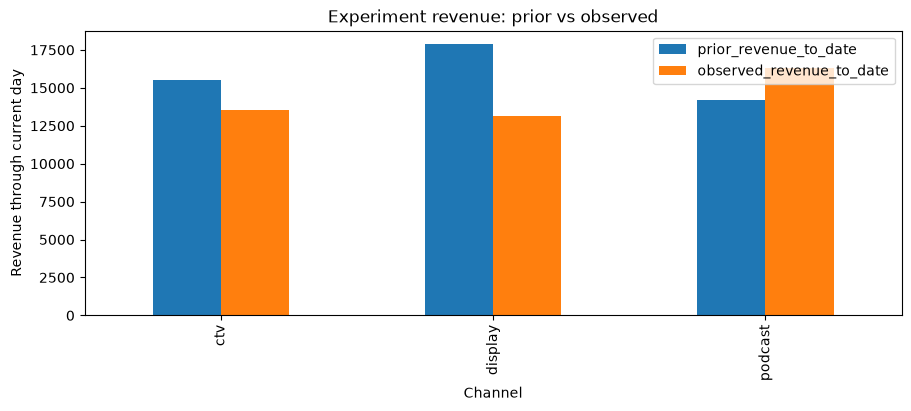

In [3]:
experiment_ids = cohorts.loc[cohorts["stage"].eq("experiment"), "cohort_id"]
cohort_channels = cohorts.set_index("cohort_id")["channel"]

planned_revenue = (
    prior_result.projections.query(
        "cohort_id in @experiment_ids and period <= @AS_OF and category == 'revenue'"
    )
    .assign(channel=lambda frame: frame["cohort_id"].map(cohort_channels))
    .groupby("channel")["amount"].sum()
)
observed_revenue = (
    observations.query(
        "cohort_id in @experiment_ids and component == 'subscription_revenue'"
    )
    .assign(channel=lambda frame: frame["cohort_id"].map(cohort_channels))
    .groupby("channel")["amount"].sum()
)
test_variance = pd.concat([
    planned_revenue.rename("prior_revenue_to_date"),
    observed_revenue.rename("observed_revenue_to_date"),
], axis=1)
test_variance["variance"] = test_variance["observed_revenue_to_date"] / test_variance["prior_revenue_to_date"] - 1
display(test_variance)

variance_figure = Figure(figsize=(9, 4), layout="constrained")
variance_ax = variance_figure.subplots()
test_variance[["prior_revenue_to_date", "observed_revenue_to_date"]].plot(
    kind="bar", ax=variance_ax, title="Experiment revenue: prior vs observed"
)
variance_ax.set(ylabel="Revenue through current day", xlabel="Channel")
display(variance_figure)

## Optimize the next 20 weeks of new-channel spend

The CFO has a fixed **$650k** new-channel budget. Podcast capacity ramps from $15k per week as inventory and creative operations scale. Display is capped at zero after the failed test.

We solve two models:

1. **Direct attribution:** allocate strictly on each channel's own cohort economics.
2. **Incrementality-aware:** enumerate a CTV-on strategy with a $14k weekly test commitment, apply the measured halo to eligible cohorts, then allocate the remaining budget optimally.

The second formulation keeps CTV's direct cohort return separate from its portfolio effect.

In [4]:
curve_spec = curve_assumptions.set_index("curve_id")
response_curve_ids = {
    "podcast_direct": "sub_podcast_actual",
    "podcast_halo": "sub_podcast_halo",
    "display": "sub_display_actual",
    "ctv": "sub_ctv_actual",
}

response_cohorts, response_spend = [], []
for label, curve_id in response_curve_ids.items():
    response_cohorts.append({
        "cohort_id": label, "acquisition_period": 0,
        "population": 1 / curve_spec.loc[curve_id, "cac"],
        "curve_id": curve_id,
    })
    response_spend.append({"period": 0, "cohort_id": label, "amount": 1.0})
response_result = tg.forecast(
    pd.DataFrame(response_cohorts), curves,
    acquisition_spend=pd.DataFrame(response_spend),
    as_of=0, forecast_end=FORECAST_END, start=0,
)

unit_cumulative_profit = {}
for label in response_curve_ids:
    daily = (
        response_result.contributions.query(
            "cohort_id == @label and category != 'activity'"
        )
        .groupby("age")["pnl_amount"].sum()
        .reindex(range(FORECAST_END + 1), fill_value=0).to_numpy(copy=True)
    )
    daily[0] -= 1.0
    unit_cumulative_profit[label] = np.cumsum(daily)


def solve_new_channel_plan(*, halo):
    rows = []
    for week in range(FUTURE_WEEKS):
        day = AS_OF + 1 + 7 * week
        for channel in ["podcast", "display", "ctv"]:
            response_label = "podcast_halo" if halo and channel == "podcast" else (
                "podcast_direct" if channel == "podcast" else channel
            )
            maximum = {
                "podcast": min(15000 + 2500 * week, 50000),
                "display": 0,
                "ctv": 18000,
            }[channel]
            minimum = 14000 if halo and channel == "ctv" else 0
            rows.append({
                "channel": channel, "week": week, "period": day,
                "minimum": minimum, "maximum": maximum,
                "terminal_profit_per_dollar": unit_cumulative_profit[response_label][FORECAST_END - day],
            })
    plan = pd.DataFrame(rows)
    solution = linprog(
        c=-plan["terminal_profit_per_dollar"],
        A_eq=np.ones((1, len(plan))), b_eq=[FUTURE_BUDGET],
        bounds=list(zip(plan["minimum"], plan["maximum"])),
        method="highs",
    )
    assert solution.success, solution.message
    plan["spend"] = solution.x
    return plan


direct_plan = solve_new_channel_plan(halo=False)
halo_plan = solve_new_channel_plan(halo=True)
allocation = pd.concat([
    direct_plan.groupby("channel")["spend"].sum().rename("direct_attribution"),
    halo_plan.groupby("channel")["spend"].sum().rename("halo_aware"),
], axis=1)
display(allocation)

assert direct_plan.groupby("channel")["spend"].sum()["podcast"] == FUTURE_BUDGET
assert direct_plan.groupby("channel")["spend"].sum()[["display", "ctv"]].sum() < 0.01
assert halo_plan.groupby("channel")["spend"].sum()["ctv"] >= 14000 * FUTURE_WEEKS - 0.01

,direct_attribution,halo_aware
channel,,
ctv,0.00,"280,000.00"
display,0.00,0.00
podcast,"650,000.00","370,000.00"


In [5]:
def scoped_overrides(*, halo):
    actual_curve = {
        "podcast": "sub_podcast_actual",
        "display": "sub_display_actual",
        "ctv": "sub_ctv_actual",
    }
    pieces = []
    for cohort in cohorts.itertuples(index=False):
        source_curve = actual_curve.get(cohort.channel)
        if halo and cohort.channel in {"paid_search", "affiliate"}:
            source_curve = f"sub_{cohort.channel}_halo"
        if source_curve is None:
            continue
        patch = curves.loc[curves["curve_id"].eq(source_curve)].copy()
        patch["curve_id"] = cohort.curve_id
        patch["cohort_id"] = cohort.cohort_id
        patch["curve_version"] = 2
        pieces.append(patch)
    return pd.concat(pieces, ignore_index=True)


def build_scenario(plan, *, halo):
    future_cohorts, future_spend = [], []
    fixed = {"paid_search": 15000, "affiliate": 9000}
    curve_map = {
        "paid_search": "sub_paid_search_halo" if halo else "sub_paid_search",
        "affiliate": "sub_affiliate_halo" if halo else "sub_affiliate",
        "podcast": "sub_podcast_halo" if halo else "sub_podcast_actual",
        "display": "sub_display_actual",
        "ctv": "sub_ctv_actual",
    }
    for week in range(FUTURE_WEEKS):
        day = AS_OF + 1 + 7 * week
        amounts = fixed | plan.loc[plan["week"].eq(week)].set_index("channel")["spend"].to_dict()
        for channel, amount in amounts.items():
            if amount <= 0.01:
                continue
            curve_id = curve_map[channel]
            cohort_id = f"future-{channel}-w{week:02d}"
            future_cohorts.append({
                "cohort_id": cohort_id,
                "acquisition_period": day,
                "population": amount / curve_spec.loc[curve_id, "cac"],
                "curve_id": curve_id,
                "channel": channel,
                "week": 16 + week,
                "stage": "future",
            })
            future_spend.append({
                "period": day, "cohort_id": cohort_id,
                "amount": amount, "channel": channel,
            })

    scenario_curves = pd.concat([curves, scoped_overrides(halo=halo)], ignore_index=True)
    return tg.forecast(
        pd.concat([cohorts, pd.DataFrame(future_cohorts)], ignore_index=True),
        scenario_curves,
        observations=observations,
        acquisition_spend=pd.concat(
            [acquisition_spend, pd.DataFrame(future_spend)], ignore_index=True
        ),
        as_of=AS_OF, forecast_end=FORECAST_END, start=0,
    )


empty_plan = direct_plan.assign(spend=0.0)
control_result = build_scenario(empty_plan, halo=False)
direct_result = build_scenario(direct_plan, halo=False)
halo_attribution_only_result = build_scenario(halo_plan, halo=False)
halo_result = build_scenario(halo_plan, halo=True)

## Compare company cash, not merely channel ROAS

Every scenario retains the same established-channel plan and non-marketing cash outflow. The two optimized expansion plans spend the same $650k, so their ending-cash difference is an incremental portfolio comparison.

The “CTV allocation, attribution only” case deliberately values the halo plan without the halo. The gap to the halo-aware result quantifies what direct attribution omits.

In [6]:
def cash_path(result):
    timeline = result.timeline()
    operating = np.cumsum(np.repeat(DAILY_OPERATING_CASH_FLOW, len(timeline)))
    return STARTING_CASH + operating + timeline["cumulative_marketing_pnl"].to_numpy()


scenarios = {
    "No new-channel expansion": control_result,
    "Direct optimizer: scale podcast": direct_result,
    "CTV allocation, attribution only": halo_attribution_only_result,
    "Incrementality-aware: podcast + CTV": halo_result,
}
summary_rows = []
for name, result in scenarios.items():
    cash = cash_path(result)
    summary_rows.append({
        "scenario": name,
        "total_acquisition_spend": result.acquisition_spend["amount"].sum(),
        "minimum_cash": cash.min(),
        "ending_cash": cash[-1],
        "marketing_pnl": result.timeline()["marketing_pnl"].sum(),
        "portfolio_roas": result.metrics().iloc[0]["roas"],
    })
scenario_summary = pd.DataFrame(summary_rows).set_index("scenario")
display(scenario_summary)

halo_increment = (
    cash_path(halo_result)[-1] - cash_path(halo_attribution_only_result)[-1]
)
future_ctv_ids = halo_result.cohorts.loc[
    halo_result.cohorts["cohort_id"].astype(str).str.startswith("future-ctv"), "cohort_id"
]
ctv_direct_contribution = halo_result.contributions.loc[
    halo_result.contributions["cohort_id"].isin(future_ctv_ids)
    & halo_result.contributions["category"].ne("activity"),
    "pnl_amount",
].sum()
ctv_direct_spend = halo_result.acquisition_spend.loc[
    halo_result.acquisition_spend["cohort_id"].isin(future_ctv_ids), "amount"
].sum()
print(f"CTV directly attributed marketing P&L: ${ctv_direct_contribution - ctv_direct_spend:,.0f}")
print(f"Modeled portfolio halo omitted by direct attribution: ${halo_increment:,.0f}")

,total_acquisition_spend,minimum_cash,ending_cash,marketing_pnl,portfolio_roas
scenario,,,,,
No new-channel expansion,"992,000.00","427,029.49","1,174,681.75","607,681.75",1.66
Direct optimizer: scale podcast,"1,642,000.00","265,832.73","1,531,074.41","964,074.41",1.64
"CTV allocation, attribution only","1,642,000.00","151,542.44","1,311,556.05","744,556.05",1.50
Incrementality-aware: podcast + CTV,"1,642,000.00","215,644.03","1,637,124.65","1,070,124.65",1.70


CTV directly attributed marketing P&L: $-124,657
Modeled portfolio halo omitted by direct attribution: $325,569


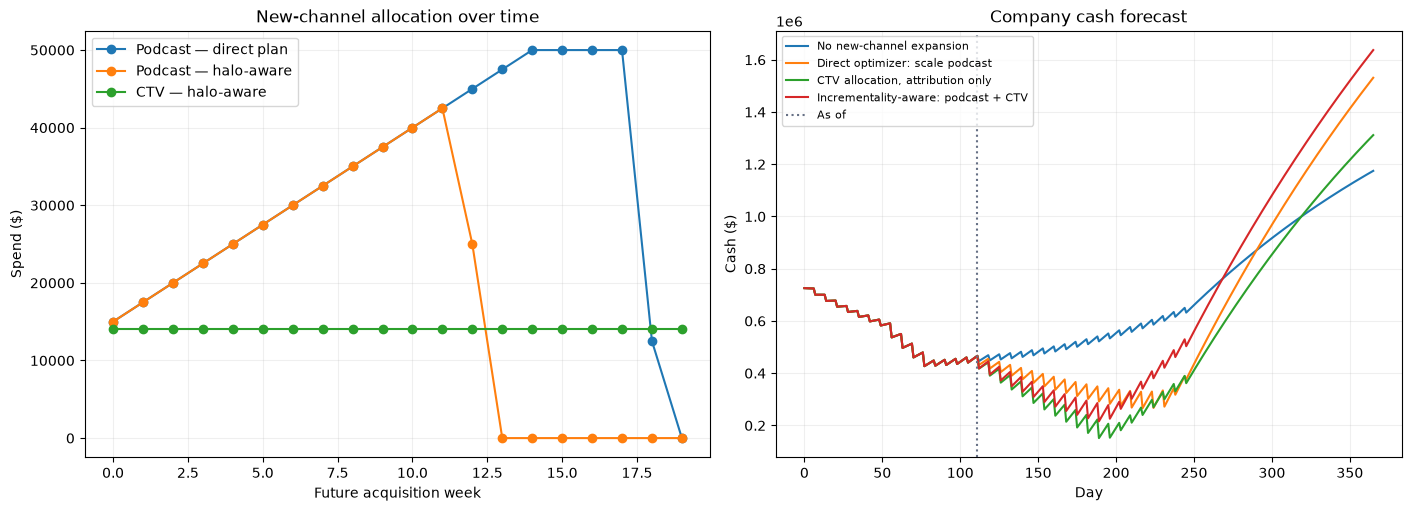

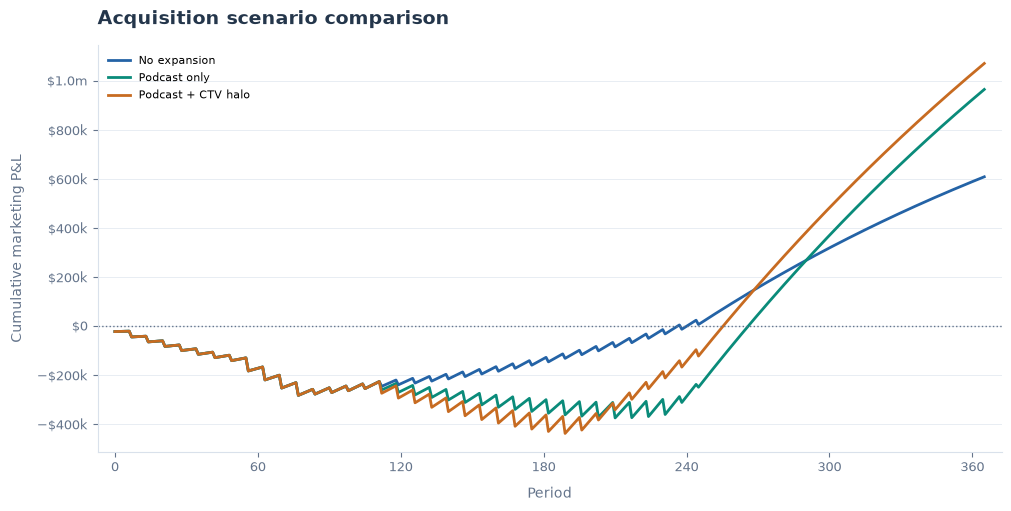

In [7]:
comparison_figure = Figure(figsize=(14, 5), layout="constrained")
allocation_ax, cash_ax = comparison_figure.subplots(1, 2)

weekly_allocations = pd.DataFrame({
    "Podcast — direct plan": direct_plan.query("channel == 'podcast'").set_index("week")["spend"],
    "Podcast — halo-aware": halo_plan.query("channel == 'podcast'").set_index("week")["spend"],
    "CTV — halo-aware": halo_plan.query("channel == 'ctv'").set_index("week")["spend"],
})
weekly_allocations.plot(ax=allocation_ax, marker="o", title="New-channel allocation over time")
allocation_ax.set(xlabel="Future acquisition week", ylabel="Spend ($)")
allocation_ax.grid(alpha=0.2)

for name, result in scenarios.items():
    cash_ax.plot(cash_path(result), label=name)
cash_ax.axvline(AS_OF, color="#667085", linestyle=":", label="As of")
cash_ax.set(title="Company cash forecast", xlabel="Day", ylabel="Cash ($)")
cash_ax.legend(fontsize=8)
cash_ax.grid(alpha=0.2)
display(comparison_figure)

scenario_chart = tg.viz.scenario_comparison({
    "No expansion": control_result,
    "Podcast only": direct_result,
    "Podcast + CTV halo": halo_result,
})
display(scenario_chart.figure)

## CFO interpretation and measurement discipline

- Podcast is a conventional winner: its own cohorts beat the prior and the optimizer scales it as capacity expands.
- Display is a conventional loser: its updated 365-day contribution is negative, so post-test spend is zero.
- CTV is the important edge case. Its directly attributed cohorts lose money, but the scenario can still create portfolio value if the retention and monetization lift across other cohorts is causal.
- That last “if” is the decision risk. In production, estimate the halo with geo holdouts, lift tests, or another causal design; carry a low/base/high halo range; and avoid counting the same conversions in both direct attribution and incrementality.
- Theseus keeps the mechanics auditable: observations remain authoritative, revised curves affect future contributions, and the CFO can compare resulting cash paths under one canonical ledger.